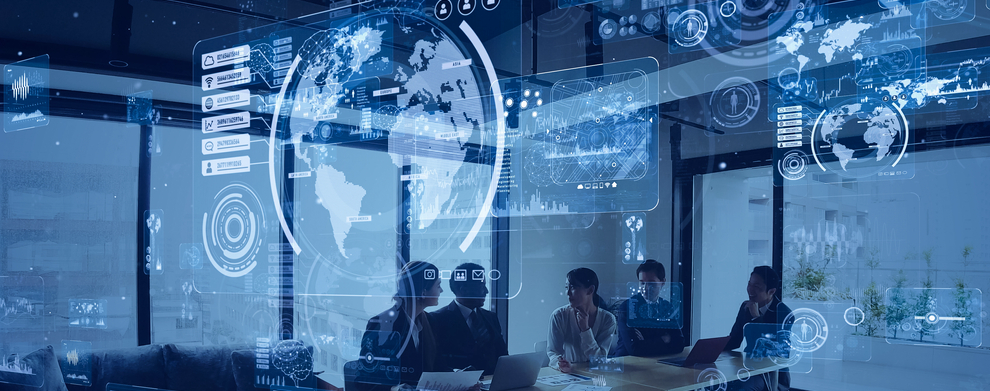

# Exercise 0 Start with Python

python is a widely used programming language in machine learning.
Many libraries implement almost all known methods of machine learning.
So it makes sense to learn python as well as the two most used libraries numpy and pandas.

## Preparation Courses

Walk through the following three online classes about python, numpy and pandas.

- https://www.w3schools.com/python/default.asp 
- https://www.w3schools.com/python/pandas/default.asp
- https://www.w3schools.com/python/numpy/default.asp



## Considerations

- With python focus on control flow (if, loops, functions) and data types (values, lists, dictionaries)
- With pandas focus of import and export, creation of dataframes, merging and slicing. It is important to understand the different types of accessing the data (e.g.loc) and the meaning of the bracket operators. 
- With numpy focus on creating arrays, multidimensional arrays, merging of data, transformations and slicing

## Assignment

The following notebook contains 10 tasks to be solved using python, pandas and numpy.

In [1]:
import pandas as pd

data = {
    "Name": ["Alice", "Bob", "Charlie", "David", "Eva"],
    "Age": [23, 25, 30, 22, 28],
    "Height_cm": [165, 170, 180, 160, 175],
    "Weight_kg": [55, 70, 80, 50, 68]
}

# Create a pandas dataframe from dictionaries
df = pd.DataFrame(data)

# Save to CSV file
df.to_csv("students.csv", index=False)

In [2]:
df_students = pd.read_csv("students.csv")

print("----------------------------------------")
print(df_students.head(5))
print("----------------------------------------")
df_students.info()

print("----------------------------------------")
print(df_students.mean(numeric_only=True))
print("----------------------------------------")
print(df_students.median(numeric_only=True))
print("----------------------------------------")
print(df_students.min(numeric_only=True))
print("----------------------------------------")
print(df_students.max(numeric_only=True))

----------------------------------------
      Name  Age  Height_cm  Weight_kg
0    Alice   23        165         55
1      Bob   25        170         70
2  Charlie   30        180         80
3    David   22        160         50
4      Eva   28        175         68
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Name       5 non-null      object
 1   Age        5 non-null      int64 
 2   Height_cm  5 non-null      int64 
 3   Weight_kg  5 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 292.0+ bytes
----------------------------------------
Age           25.6
Height_cm    170.0
Weight_kg     64.6
dtype: float64
----------------------------------------
Age           25.0
Height_cm    170.0
Weight_kg     68.0
dtype: float64
----------------------------------------
Age           22
Height_cm    160


# Task 2: Handling Date Columns - Loading CSV and Date Conversion

Learn how to handle date columns and convert them into Pandas datetime objects.

- Load a CSV file containing a column with dates.
- Convert the date column to a Pandas datetime object.
- Extract the year, month, and day from the date column.


In [3]:
data_dates = {
    "Name": ["Alice", "Bob", "Charlie", "David", "Eva"],
    "Join_Date": ["2022-01-15", "2021-12-12", "2020-06-10", "2019-11-11", "2023-07-22"]
}

df = pd.DataFrame(data_dates)
df.to_csv("students_dates.csv", index=False)

In [4]:
df_dates = pd.read_csv("students_dates.csv")

df_dates["Join_Date"] = pd.to_datetime(df_dates["Join_Date"])

df_dates["Year"] = df_dates["Join_Date"].dt.year
df_dates["Month"] = df_dates["Join_Date"].dt.month
df_dates["Day"] = df_dates["Join_Date"].dt.day

print("----------------------------------------")
print(df_dates)

----------------------------------------
      Name  Join_Date  Year  Month  Day
0    Alice 2022-01-15  2022      1   15
1      Bob 2021-12-12  2021     12   12
2  Charlie 2020-06-10  2020      6   10
3    David 2019-11-11  2019     11   11
4      Eva 2023-07-22  2023      7   22


# Task 3: Column Selection and Row Filtering

Practice selecting specific columns and filtering rows based on conditions.

- Select and display the Name and Age columns from the DataFrame.
- Filter out students who are older than 25 years and display the result.

In [5]:
# Select columns
print("----------------------------------------")
print(df_students[["Name", "Age"]])

# Students older than 25
print("----------------------------------------")
print(df_students[df_students["Age"] > 25])

----------------------------------------
      Name  Age
0    Alice   23
1      Bob   25
2  Charlie   30
3    David   22
4      Eva   28
----------------------------------------
      Name  Age  Height_cm  Weight_kg
2  Charlie   30        180         80
4      Eva   28        175         68


# Task 4: Slicing and Indexing Rows

Learn how to slice rows and use different types of indexing.

- Display the first 3 rows of the DataFrame.
- Use .iloc to select the 2nd and 4th row.
- Use .loc to select rows where the "Name" is "Charlie" or "Eva".

In [6]:
# First three rows
print("----------------------------------------")
print(df_students.head(3))

# Second and fourth rows
print("----------------------------------------")
print(df_students.iloc[[1, 3]])

# Students named Charlie or Eva
print("----------------------------------------")
print(df_students.loc[(df_students["Name"] == "Charlie") |
                      (df_students["Name"] == "Eva")])

----------------------------------------
      Name  Age  Height_cm  Weight_kg
0    Alice   23        165         55
1      Bob   25        170         70
2  Charlie   30        180         80
----------------------------------------
    Name  Age  Height_cm  Weight_kg
1    Bob   25        170         70
3  David   22        160         50
----------------------------------------
      Name  Age  Height_cm  Weight_kg
2  Charlie   30        180         80
4      Eva   28        175         68


# Task 5: Handling Missing Values - Replacement and Removal

Understand how to detect, replace, and remove missing values.

- Take the generated DataFrame with some missing values.
- Replace missing values in value columns with the column's mean.
- Drop rows that have any missing values.

In [7]:
import numpy as np

data_missing = {
    "Name": ["Alice", "Bob", np.nan, "David", "Eva"],
    "Age": [23, np.nan, 30, 22, np.nan],
    "Height_cm": [165, 170, 180, np.nan, 175]
}

df = pd.DataFrame(data_missing)

In [8]:
# Copy original data
df_filled = df.copy()

# Replace missing values with mean
df_filled["Age"] = df_filled["Age"].fillna(df_filled["Age"].mean())
df_filled["Height_cm"] = df_filled["Height_cm"].fillna(df_filled["Height_cm"].mean())

print("----------------------------------------")
print(df_filled)

# Remove rows with missing values
df_removed = df.dropna()

print("----------------------------------------")
print(df_removed)

----------------------------------------
    Name   Age  Height_cm
0  Alice  23.0      165.0
1    Bob  25.0      170.0
2    NaN  30.0      180.0
3  David  22.0      172.5
4    Eva  25.0      175.0
----------------------------------------
    Name   Age  Height_cm
0  Alice  23.0      165.0


# Task 6: Data Concatenation and Merging

Learn how to concatenate multiple DataFrames and merge them based on a common column.

- Take the two separate DataFrames: students and scores.
- Concatenate them along the columns (students and scores)
- Concatenate them along the rows (students and students_2)
- Merge the DataFrames based on a common column (result of concatenate along rows and scores)

In [9]:
students = pd.DataFrame({
    "StudentID": [1, 2, 3],
    "Name": ["Alice", "Bob", "Charlie"]
})

students_2 = pd.DataFrame({
    "StudentID": [4, 5, 6],
    "Name": ["Ferdl", "Hanni", "Sepp"]
})

scores = pd.DataFrame({
    "StudentID": [1, 2, 4],
    "Score": [85, 90, 88]
})


In [10]:
# Combine columns
result1 = pd.concat([students, scores], axis=1)
print("----------------------------------------")
print(result1)

# Combine rows
result2 = pd.concat([students, students_2], ignore_index=True)
print("----------------------------------------")
print(result2)

# Merge using StudentID
result3 = pd.merge(result2, scores, on="StudentID", how="left")
print("----------------------------------------")
print(result3)

----------------------------------------
   StudentID     Name  StudentID  Score
0          1    Alice          1     85
1          2      Bob          2     90
2          3  Charlie          4     88
----------------------------------------
   StudentID     Name
0          1    Alice
1          2      Bob
2          3  Charlie
3          4    Ferdl
4          5    Hanni
5          6     Sepp
----------------------------------------
   StudentID     Name  Score
0          1    Alice   85.0
1          2      Bob   90.0
2          3  Charlie    NaN
3          4    Ferdl   88.0
4          5    Hanni    NaN
5          6     Sepp    NaN


# Task 7: Introduction to NumPy - Basic Array Creation and Manipulation

Familiarize yourself with creating NumPy arrays and performing basic manipulations.

- Take a NumPy array of 10 random integers.
- Reshape the array into a 2x5 matrix.
- Slice the array to get specific elements and rows/columns (element at (0,2), first row, second column)

In [11]:
import numpy as np

array = np.random.randint(0, 100, size=10)


In [12]:
# Reshape array
matrix = array.reshape(2, 5)
print("----------------------------------------")
print(matrix)

# Element at row 0, column 2
print("----------------------------------------")
print(matrix[0, 2])

# First row
print("----------------------------------------")
print(matrix[0, :])

# Second column
print("----------------------------------------")
print(matrix[:, 1])

----------------------------------------
[[48 92 63  4 74]
 [69 27 38 47 59]]
----------------------------------------
63
----------------------------------------
[48 92 63  4 74]
----------------------------------------
[92 27]


# Task 8: Array Operations - Element-wise and Matrix Operations

Practice basic arithmetic operations and matrix manipulations in NumPy.

- Create two NumPy arrays of size 3x3 with random numbers.
- Perform element-wise addition, subtraction, multiplication, and division.
- Calculate the dot product of the two arrays.

In [13]:
# Create random arrays
a = np.random.randint(1, 10, (3, 3))
b = np.random.randint(1, 10, (3, 3))

print("----------------------------------------")
print(a)
print("----------------------------------------")
print(b)

# Basic operations
print("----------------------------------------")
print(a + b)
print("----------------------------------------")
print(a - b)
print("----------------------------------------")
print(a * b)
print("----------------------------------------")
print(a / b)

# Matrix multiplication
print("----------------------------------------")
print(np.dot(a, b))

----------------------------------------
[[9 4 1]
 [1 2 3]
 [1 2 2]]
----------------------------------------
[[2 7 8]
 [4 3 3]
 [9 4 3]]
----------------------------------------
[[11 11  9]
 [ 5  5  6]
 [10  6  5]]
----------------------------------------
[[ 7 -3 -7]
 [-3 -1  0]
 [-8 -2 -1]]
----------------------------------------
[[18 28  8]
 [ 4  6  9]
 [ 9  8  6]]
----------------------------------------
[[4.5        0.57142857 0.125     ]
 [0.25       0.66666667 1.        ]
 [0.11111111 0.5        0.66666667]]
----------------------------------------
[[43 79 87]
 [37 25 23]
 [28 21 20]]


# Task 9: Normalization and Standardization of NumPy Array Values

Learn how to normalize and standardize the values in a NumPy array.

Normalization is the process of scaling the values of an array so that they fall within a specific range, usually between 0 and 1.

Standardization (or Z-score normalization) transforms the data so that it has a mean of 0 and a standard deviation of 1.


- Take a 1D NumPy array of 10 random float values.
- Normalize the array so that all values lie between 0 and 1.
- Standardize the array

In [14]:
array = np.random.uniform(-10, 10, 10)


In [15]:
# Normalization
minimum = np.min(array)
maximum = np.max(array)

normalized = (array - minimum) / (maximum - minimum)

# Standardization
mean = np.mean(array)
std = np.std(array)

standardized = (array - mean) / std

print("----------------------------------------")
print(normalized)
print("----------------------------------------")
print(standardized)

----------------------------------------
[0.15461794 0.78298413 0.         0.13128574 0.43932324 0.00842679
 1.         0.27495325 0.58603857 0.10289404]
----------------------------------------
[-0.5925921   1.33242631 -1.06626872 -0.66407097  0.27961102 -1.04045301
  1.99726083 -0.22394133  0.72907776 -0.75104978]


# Task 10: One-Hot Encoding Using NumPy

Implement one-hot encoding for categorical data using NumPy.

A one-hot encoding takes a set of strings and assigns a unique integer index to each string. The index
represents a position in an array. The array has the same length as the count of different strings in the set.
If a strings needs to be represented, take the index of the string and assign a 1 at the indexed position. All other
values in the array are 0.

- Take a NumPy array of categorical labels: ["dog", "cat", "bird", "dog", "bird"].
- Convert these labels into a one-hot encoded format using NumPy.

In [16]:
labels = np.array(["dog", "cat", "bird", "dog", "bird"])
unique_labels = np.unique(labels)

In [17]:
# Create matrix filled with zeros
one_hot = np.zeros((len(labels), len(unique_labels)), dtype=int)

# Set matching positions to 1
for i in range(len(labels)):
    for j in range(len(unique_labels)):
        if labels[i] == unique_labels[j]:
            one_hot[i, j] = 1

print("----------------------------------------")
print(unique_labels)
print("----------------------------------------")
print(one_hot)

----------------------------------------
['bird' 'cat' 'dog']
----------------------------------------
[[0 0 1]
 [0 1 0]
 [1 0 0]
 [0 0 1]
 [1 0 0]]
